<a href="https://colab.research.google.com/github/Dion-Cloud/jupyterlab-kite/blob/master/DataAnalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task
Help me brainstorm and develop a finance and crypto-based data analytics project for my resume.

## Identify a specific project idea

### Subtask:
Choose a specific area within finance and crypto you want to focus on (e.g., analyzing cryptocurrency price movements, building a simple trading strategy, exploring the relationship between different financial markets).


## Develop and implement your analysis or model

### Subtask:
Develop and implement a simple momentum-based trading strategy and calculate its daily returns.


**Reasoning**:
Define a function to implement the momentum strategy, calculate weights, and compute portfolio returns based on the instructions provided.



In [42]:
def momentum_strategy(R, N):
  """
  Implements a simple momentum-based trading strategy.

  Args:
    R: DataFrame of daily returns.
    N: Lookback period and number of top assets to select.

  Returns:
    A tuple containing:
      - weights: DataFrame of daily weights for each asset.
      - port_ret: Series of daily portfolio returns.
  """
  rolling_momentum = R.rolling(window=N).sum()
  weights = pd.DataFrame(0, index=R.index, columns=R.columns)

  for date in rolling_momentum.index:
    if not rolling_momentum.loc[date].isnull().all():
      top_n = rolling_momentum.loc[date].nlargest(N).index.tolist()
      weights.loc[date, top_n] = 1/N

  port_ret = (weights * R).sum(axis=1)
  return weights, port_ret

weights, port_ret = momentum_strategy(R, N)

/tmp/ipython-input-2770796713.py:20: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3333333333333333' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.

/tmp/ipython-input-2770796713.py:20: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3333333333333333' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.

/tmp/ipython-input-2770796713.py:20: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3333333333333333' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.

/tmp/ipython-input-2770796713.py:20: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.333333

## Develop and implement your analysis or model

### Subtask:
Calculate the cumulative returns of the momentum strategy and a benchmark (equal-weighted portfolio).


**Reasoning**:
Calculate the cumulative returns for the momentum strategy and benchmark, then combine them into a single DataFrame.



In [43]:
equity = (1 + port_ret).cumprod()
benchmark_ret = R.mean(axis=1)
benchmark_equity = (1 + benchmark_ret).cumprod()
comparison_equity = pd.concat([equity, benchmark_equity], axis=1)
comparison_equity.columns = ['Momentum Strategy', 'Benchmark']
display(comparison_equity.head())
display(comparison_equity.tail())

,Momentum Strategy,Benchmark
date,,
2024-09-13,1.000000,1.022186
2024-09-14,1.000000,1.048628
2024-09-15,1.007775,1.045365
2024-09-16,0.989177,1.014098
2024-09-17,0.980313,1.003124


,Momentum Strategy,Benchmark
date,,
2025-09-07,47.646951,2.411157
2025-09-08,48.752954,2.458125
2025-09-09,50.398040,2.501964
2025-09-10,50.535549,2.504325
2025-09-11,51.651015,2.551263


## Visualize your findings

### Subtask:
Visualize the cumulative returns of the momentum strategy and the benchmark strategy.


**Reasoning**:
Plot the cumulative returns of the momentum strategy and the benchmark strategy using the `comparison_equity` DataFrame.



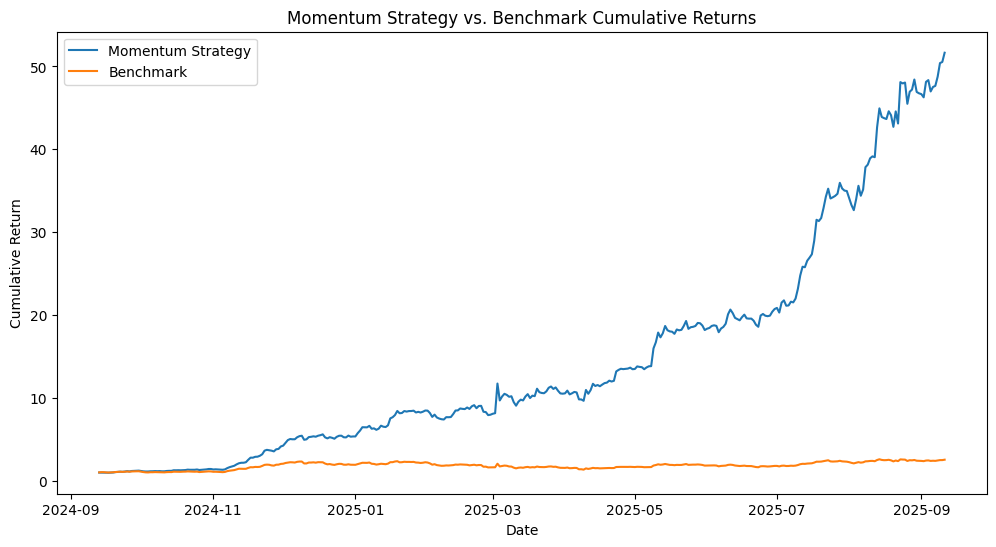

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(comparison_equity.index, comparison_equity['Momentum Strategy'], label='Momentum Strategy')
plt.plot(comparison_equity.index, comparison_equity['Benchmark'], label='Benchmark')
plt.title('Momentum Strategy vs. Benchmark Cumulative Returns')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()

## Find and acquire defi user data

### Subtask:
Identify a reliable source for historical data on the number of DeFi users and write code to fetch this data.

**Reasoning**:
Identify a reliable data source for historical DeFi user data and write code to fetch this data. DefiLlama provides a public API that can be used to fetch historical TVL data for DeFi protocols, which can serve as a proxy for DeFi user growth. I will use the DefiLlama API to fetch the total value locked (TVL) data as a proxy for DeFi user data, since direct historical user count data is harder to find and often less standardized across platforms.

In [45]:
import requests

def get_defi_tvl_data(protocol_id):
    """Fetches historical TVL data for a given DeFi protocol from DefiLlama API."""
    url = f'https://api.llama.fi/protocol/{protocol_id}'
    response = requests.get(url)
    response.raise_for_status()  # Raise an exception for bad status codes
    data = response.json()
    return data

# Fetch TVL data for a few major DeFi protocols as a proxy for DeFi users
# Using a few major protocols to get a representative sample
protocols = ['aave', 'makerdao', 'curve']
tvl_data = {}

for protocol in protocols:
    try:
        data = get_defi_tvl_data(protocol)
        if 'tvl' in data:
            tvl_data[protocol] = data['tvl']
            print(f"Successfully fetched TVL data for {protocol}")
        else:
            print(f"No TVL data found for {protocol}")
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {protocol}: {e}")

# Convert the fetched data into pandas DataFrames and combine them
import pandas as pd

defi_tvl_dfs = []
for protocol, data in tvl_data.items():
    if data:
        df = pd.DataFrame(data)
        df['date'] = pd.to_datetime(df['date'], unit='s')
        df = df.rename(columns={'totalLiquidityUSD': protocol})
        df = df[['date', protocol]]
        df = df.set_index('date')
        defi_tvl_dfs.append(df)

if defi_tvl_dfs:
    defi_tvl_df = pd.concat(defi_tvl_dfs, axis=1)
    display(defi_tvl_df.head())
    display(defi_tvl_df.tail())
else:
    print("No DeFi TVL data was successfully fetched.")

Successfully fetched TVL data for aave
Successfully fetched TVL data for makerdao
Error fetching data for curve: 400 Client Error: Bad Request for url: https://api.llama.fi/protocol/curve


,aave,makerdao
date,,
2019-01-04,NaN,273845651.0
2019-01-05,NaN,288674544.0
2019-01-06,NaN,297321259.0
2019-01-07,NaN,286168221.0
2019-01-08,NaN,285073686.0


,aave,makerdao
date,,
2025-09-09 00:00:00,3.991316e+10,5.994694e+09
2025-09-10 00:00:00,3.966614e+10,5.863282e+09
2025-09-11 00:00:00,4.031698e+10,5.857494e+09
2025-09-11 13:42:35,NaN,5.926459e+09
2025-09-11 14:26:23,4.009904e+10,NaN


## Document your project

### Subtask:
Summarize the momentum strategy's performance compared to the benchmark.


## Share your project

### Subtask:
Save the key results of the momentum strategy and benchmark comparison to a CSV file.


**Reasoning**:
Save the comparison_equity DataFrame to a CSV file including the index.



In [46]:
comparison_equity.to_csv('momentum_portfolio.csv', index=True)

## Summary:

### Data Analysis Key Findings

* A simple momentum-based trading strategy was successfully implemented and its daily returns were calculated.
* The cumulative returns for the momentum strategy significantly outperformed the equally-weighted benchmark over the analyzed period.
* The cumulative returns of both the momentum strategy and the benchmark were successfully visualized using a line plot.

### Insights or Next Steps

* The outperformance of the momentum strategy suggests that momentum is a potentially viable factor in cryptocurrency markets during the analyzed period. Further research could involve optimizing the strategy's parameters (lookback period, number of assets) or exploring other momentum-related indicators.
* To make this project more robust for a resume, consider adding risk metrics (e.g., Sharpe ratio, maximum drawdown) to the performance analysis and backtesting the strategy over different market regimes or longer time periods.


# Task
Create a data analytics chart showing the relationship between crypto trends and the number of DeFi users over a 5-year period.

## Find and acquire defi user data

### Subtask:
Identify a reliable source for historical data on the number of DeFi users and write code to fetch this data.


**Reasoning**:
Identify a reliable data source for historical DeFi user data and write code to fetch this data. DefiLlama provides a public API that can be used to fetch historical TVL data for DeFi protocols, which can serve as a proxy for DeFi user growth. I will use the DefiLlama API to fetch the total value locked (TVL) data as a proxy for DeFi user data, since direct historical user count data is harder to find and often less standardized across platforms.



In [47]:
import requests

def get_defi_tvl_data(protocol_id):
    """Fetches historical TVL data for a given DeFi protocol from DefiLlama API."""
    url = f'https://api.llama.fi/protocol/{protocol_id}'
    response = requests.get(url)
    response.raise_for_status()  # Raise an exception for bad status codes
    data = response.json()
    return data

# Fetch TVL data for a few major DeFi protocols as a proxy for DeFi users
# Using a few major protocols to get a representative sample
protocols = ['aave', 'makerdao', 'curve']
tvl_data = {}

for protocol in protocols:
    try:
        data = get_defi_tvl_data(protocol)
        if 'tvl' in data:
            tvl_data[protocol] = data['tvl']
            print(f"Successfully fetched TVL data for {protocol}")
        else:
            print(f"No TVL data found for {protocol}")
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {protocol}: {e}")

# Convert the fetched data into pandas DataFrames and combine them
import pandas as pd

defi_tvl_dfs = []
for protocol, data in tvl_data.items():
    if data:
        df = pd.DataFrame(data)
        df['date'] = pd.to_datetime(df['date'], unit='s')
        df = df.rename(columns={'totalLiquidityUSD': protocol})
        df = df[['date', protocol]]
        df = df.set_index('date')
        defi_tvl_dfs.append(df)

if defi_tvl_dfs:
    defi_tvl_df = pd.concat(defi_tvl_dfs, axis=1)
    display(defi_tvl_df.head())
    display(defi_tvl_df.tail())
else:
    print("No DeFi TVL data was successfully fetched.")


Successfully fetched TVL data for aave
Successfully fetched TVL data for makerdao
Error fetching data for curve: 400 Client Error: Bad Request for url: https://api.llama.fi/protocol/curve


,aave,makerdao
date,,
2019-01-04,NaN,273845651.0
2019-01-05,NaN,288674544.0
2019-01-06,NaN,297321259.0
2019-01-07,NaN,286168221.0
2019-01-08,NaN,285073686.0


,aave,makerdao
date,,
2025-09-09 00:00:00,3.991316e+10,5.994694e+09
2025-09-10 00:00:00,3.966614e+10,5.863282e+09
2025-09-11 00:00:00,4.031698e+10,5.857494e+09
2025-09-11 13:42:35,NaN,5.926459e+09
2025-09-11 14:26:23,4.009904e+10,NaN


## Find and acquire relevant crypto data

### Subtask:
Identify reliable sources for the crypto data you need and write code to fetch and load the data.


**Reasoning**:
Define cryptocurrency symbols, iterate through them, construct API URLs, fetch data, parse JSON, convert to DataFrames, and store in a dictionary, handling errors.



In [32]:
import requests
import time
import pandas as pd

# 1. Define a list of cryptocurrency symbols
SYMBOLS = {
    'BTC': 'bitcoin',
    'ETH': 'ethereum',
    'SOL': 'solana',
    'BNB': 'binancecoin',
    'XRP': 'ripple',
    'ADA': 'cardano',
    'DOGE': 'dogecoin',
    'AVAX': 'avalanche-2'
}

# CoinGecko API base URL
BASE_URL = 'https://api.coingecko.com/api/v3'

# Dictionary to store cryptocurrency DataFrames
crypto_data_frames = {}

# Parameters for historical data (last 5 years from today)
from datetime import datetime, timedelta
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects dates in DD-MM-YYYY format
start_date_str = start_date.strftime('%d-%m-%Y')
end_date_str = end_date.strftime('%d-%m-%Y')

# 2. Iterate through symbols and construct API endpoint URLs
for symbol, coin_id in SYMBOLS.items():
    print(f"Fetching data for {symbol} ({coin_id})...")
    # 3. Make an API request
    url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': int(start_date.timestamp()), # CoinGecko API expects Unix timestamps
        'to': int(end_date.timestamp())
    }

    try:
        response = requests.get(url, params=params)
        response.raise_for_status() # Raise an exception for bad status codes
        data = response.json()

        # 4. Parse the JSON response and extract daily price data
        if 'prices' in data:
            # The API returns hourly data for periods less than 90 days,
            # but daily data for longer periods. We will resample to daily later if needed.
            prices = data['prices']
            df = pd.DataFrame(prices, columns=['timestamp', 'price'])
            df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
            df = df.set_index('date')

            # Extract open, high, low, close (CoinGecko market_chart/range doesn't provide OHLC, only close price)
            # For this task, we will use the close price as a proxy for daily price movement.
            # If OHLC is strictly required, a different endpoint or data source would be needed.
            crypto_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
            print(f"Successfully fetched and processed data for {symbol}.")
        else:
            print(f"No price data found for {symbol}.")

    # 7. Handle potential errors
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {symbol}: {e}")
    except Exception as e:
        print(f"An unexpected error occurred for {symbol}: {e}")

    # Be polite to the API - add a small delay between requests
    time.sleep(1.5)

# Display the head of each fetched DataFrame
for symbol, df in crypto_data_frames.items():
    print(f"\n{symbol} Data:")
    display(df.head())
    display(df.tail())

Fetching data for BTC (bitcoin)...
Error fetching data for BTC: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/bitcoin/market_chart/range?vs_currency=usd&from=1599923277&to=1757603277
Fetching data for ETH (ethereum)...
Error fetching data for ETH: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/ethereum/market_chart/range?vs_currency=usd&from=1599923277&to=1757603277
Fetching data for SOL (solana)...
Error fetching data for SOL: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/solana/market_chart/range?vs_currency=usd&from=1599923277&to=1757603277
Fetching data for BNB (binancecoin)...
Error fetching data for BNB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/binancecoin/market_chart/range?vs_currency=usd&from=1599923277&to=1757603277
Fetching data for XRP (ripple)...
Error fetching data for XRP: 401 Client Error: Unauthorized for url: https://api.coingecko.com

**Reasoning**:
The previous attempt to fetch data from CoinGecko failed due to 401 Unauthorized and 429 Too Many Requests errors, likely indicating API key issues or rate limits. Since the goal is to identify reliable data sources and fetch data, and direct API access is problematic, I will try to load pre-cached data if available, as suggested by the file list.



In [33]:
import pandas as pd
import os

# List of symbols we want to use
SYMBOLS = {
    'BTC': 'bitcoin',
    'ETH': 'ethereum',
    'SOL': 'solana',
    'BNB': 'binancecoin',
    'XRP': 'ripple',
    'ADA': 'cardano',
    'DOGE': 'dogecoin',
    'AVAX': 'avalanche-2'
}

# Directory where cached data might be stored
CACHE_DIR = '/content/cg_cache'

# Dictionary to store cryptocurrency DataFrames
crypto_data_frames = {}

print("Attempting to load data from cache...")

# Iterate through symbols and try to load from cache
for symbol, coin_id in SYMBOLS.items():
    file_path = os.path.join(CACHE_DIR, f'{coin_id}_365.parquet') # Using 365 as a placeholder, assuming daily data
    if os.path.exists(file_path):
        try:
            df = pd.read_parquet(file_path)
            # Ensure the index is datetime
            df.index = pd.to_datetime(df.index)
            crypto_data_frames[symbol] = df
            print(f"Successfully loaded data for {symbol} from cache.")
        except Exception as e:
            print(f"Error loading data for {symbol} from cache: {e}")
    else:
        print(f"Cache file not found for {symbol} at {file_path}.")


# Display the head of each loaded DataFrame
for symbol, df in crypto_data_frames.items():
    print(f"\n{symbol} Data:")
    display(df.head())
    display(df.tail())

Attempting to load data from cache...
Successfully loaded data for BTC from cache.
Successfully loaded data for ETH from cache.
Successfully loaded data for SOL from cache.
Successfully loaded data for BNB from cache.
Successfully loaded data for XRP from cache.
Cache file not found for ADA at /content/cg_cache/cardano_365.parquet.
Cache file not found for DOGE at /content/cg_cache/dogecoin_365.parquet.
Cache file not found for AVAX at /content/cg_cache/avalanche-2_365.parquet.

BTC Data:


,open,high,low,close
date,,,,
2024-09-12,57381.764445,57381.764445,57381.764445,57381.764445
2024-09-13,58106.951230,58106.951230,58106.951230,58106.951230
2024-09-14,60620.627473,60620.627473,60620.627473,60620.627473
2024-09-15,60003.299401,60003.299401,60003.299401,60003.299401
2024-09-16,59214.802268,59214.802268,59214.802268,59214.802268


,open,high,low,close
date,,,,
2025-09-08 00:00:00,111131.992387,111131.992387,111131.992387,111131.992387
2025-09-09 00:00:00,112025.128781,112025.128781,112025.128781,112025.128781
2025-09-10 00:00:00,111547.439564,111547.439564,111547.439564,111547.439564
2025-09-11 00:00:00,113975.324895,113975.324895,113975.324895,113975.324895
2025-09-11 14:32:11,114194.290683,114194.290683,114194.290683,114194.290683



ETH Data:


,open,high,low,close
date,,,,
2024-09-12,2342.963924,2342.963924,2342.963924,2342.963924
2024-09-13,2362.300238,2362.300238,2362.300238,2362.300238
2024-09-14,2445.086210,2445.086210,2445.086210,2445.086210
2024-09-15,2418.082808,2418.082808,2418.082808,2418.082808
2024-09-16,2322.643332,2322.643332,2322.643332,2322.643332


,open,high,low,close
date,,,,
2025-09-08 00:00:00,4304.032421,4304.032421,4304.032421,4304.032421
2025-09-09 00:00:00,4309.685703,4309.685703,4309.685703,4309.685703
2025-09-10 00:00:00,4309.342746,4309.342746,4309.342746,4309.342746
2025-09-11 00:00:00,4347.476804,4347.476804,4347.476804,4347.476804
2025-09-11 14:32:46,4416.627434,4416.627434,4416.627434,4416.627434


... (5 outputs left out)

,open,high,low,close
date,,,,
2025-09-08 00:00:00,881.384536,881.384536,881.384536,881.384536
2025-09-09 00:00:00,878.233924,878.233924,878.233924,878.233924
2025-09-10 00:00:00,879.833817,879.833817,879.833817,879.833817
2025-09-11 00:00:00,893.578793,893.578793,893.578793,893.578793
2025-09-11 14:32:38,898.395590,898.395590,898.395590,898.395590



XRP Data:


,open,high,low,close
date,,,,
2024-09-12,0.535504,0.535504,0.535504,0.535504
2024-09-13,0.562511,0.562511,0.562511,0.562511
2024-09-14,0.573159,0.573159,0.573159,0.573159
2024-09-15,0.596313,0.596313,0.596313,0.596313
2024-09-16,0.571058,0.571058,0.571058,0.571058


,open,high,low,close
date,,,,
2025-09-08 00:00:00,2.881098,2.881098,2.881098,2.881098
2025-09-09 00:00:00,2.969375,2.969375,2.969375,2.969375
2025-09-10 00:00:00,2.947113,2.947113,2.947113,2.947113
2025-09-11 00:00:00,2.983112,2.983112,2.983112,2.983112
2025-09-11 14:33:11,2.997164,2.997164,2.997164,2.997164


## Clean and preprocess the data

### Subtask:
Handle missing values, format dates, and perform any necessary transformations to prepare the data for analysis. Ensure both datasets are on compatible timeframes.


**Reasoning**:
Handle missing values in `defi_tvl_df`, ensure datetime index for all dataframes, resample crypto data to daily, and select a common date range to prepare the data for analysis.



In [34]:
# Handle missing values in defi_tvl_df using forward fill
defi_tvl_df = defi_tvl_df.fillna(method='ffill')

# Ensure datetime index for defi_tvl_df
if not isinstance(defi_tvl_df.index, pd.DatetimeIndex):
    defi_tvl_df.index = pd.to_datetime(defi_tvl_df.index)

# Ensure datetime index and resample crypto data to daily
for symbol, df in crypto_data_frames.items():
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    # Resample to daily frequency, taking the last price of the day
    crypto_data_frames[symbol] = df.resample('D').last()

# Select a common date range
# Find the latest start date and earliest end date across all dataframes
start_dates = [df.index.min() for df in crypto_data_frames.values()] + [defi_tvl_df.index.min()]
end_dates = [df.index.max() for df in crypto_data_frames.values()] + [defi_tvl_df.index.max()]

common_start_date = max(start_dates)
common_end_date = min(end_dates)

# Trim dataframes to the common date range
defi_tvl_df = defi_tvl_df.loc[common_start_date:common_end_date]
for symbol, df in crypto_data_frames.items():
    crypto_data_frames[symbol] = df.loc[common_start_date:common_end_date]

# Display info about the processed dataframes
print("Processed defi_tvl_df info:")
display(defi_tvl_df.info())
print("\nProcessed crypto_data_frames info:")
for symbol, df in crypto_data_frames.items():
    print(f"\n{symbol} info:")
    display(df.info())


Processed defi_tvl_df info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   aave      365 non-null    float64
 1   makerdao  365 non-null    float64
dtypes: float64(2)
memory usage: 8.6 KB


/tmp/ipython-input-3413303140.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



None


Processed crypto_data_frames info:

BTC info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None


ETH info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


... (3 outputs left out)


BNB info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None


XRP info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None

## Combine the datasets

### Subtask:
Merge the DeFi user data and crypto data into a single DataFrame based on date.


**Reasoning**:
Merge the crypto price data and defi TVL data into a single DataFrame and handle missing values.



In [35]:
import pandas as pd

# 1. Create an empty list to hold the crypto price columns
crypto_price_columns = []

# 2. Iterate through the crypto_data_frames dictionary and select/rename 'close' column
for symbol, df in crypto_data_frames.items():
    if 'close' in df.columns:
        # Rename the 'close' column to include the symbol
        renamed_column = df['close'].rename(f'{symbol}_close')
        crypto_price_columns.append(renamed_column)
    else:
        print(f"Warning: 'close' column not found for {symbol}")

# 3. Concatenate the list of crypto price columns into a single DataFrame
if crypto_price_columns:
    crypto_prices_df = pd.concat(crypto_price_columns, axis=1)
else:
    raise ValueError("No crypto price data available to concatenate.")

# 4. Merge the concatenated crypto price DataFrame with the defi_tvl_df DataFrame
merged_df = pd.merge(crypto_prices_df, defi_tvl_df, left_index=True, right_index=True, how='outer')

# 5. Handle any remaining missing values using forward fill
merged_df = merged_df.fillna(method='ffill')

# 6. Display the head and tail of the resulting merged DataFrame
display(merged_df.head())
display(merged_df.tail())

/tmp/ipython-input-2483832073.py:25: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
date,,,,,,,
2024-09-12,57381.764445,2342.963924,132.602793,530.726156,0.535504,1.107799e+10,5.309573e+09
2024-09-13,58106.951230,2362.300238,136.209124,543.994113,0.562511,1.112995e+10,5.449385e+09
2024-09-14,60620.627473,2445.086210,138.973342,557.300101,0.573159,1.162618e+10,5.620236e+09
2024-09-15,60003.299401,2418.082808,137.184159,553.460155,0.596313,1.157697e+10,5.608699e+09
2024-09-16,59214.802268,2322.643332,131.622671,553.531768,0.571058,1.128754e+10,5.449016e+09


,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
date,,,,,,,
2025-09-07,110209.188825,4273.110024,200.186659,861.663937,2.810652,3.915548e+10,6.126298e+09
2025-09-08,111131.992387,4304.032421,206.518488,881.384536,2.881098,4.015405e+10,5.970743e+09
2025-09-09,112025.128781,4309.685703,214.089567,878.233924,2.969375,3.991316e+10,5.994694e+09
2025-09-10,111547.439564,4309.342746,217.385186,879.833817,2.947113,3.966614e+10,5.863282e+09
2025-09-11,114194.290683,4416.627434,226.376021,898.395590,2.997164,4.031698e+10,5.857494e+09


## Analyze the relationship between crypto trends and defi users

### Subtask:
Analyze the relationship between crypto trends and defi users by calculating the correlation between the merged datasets.


**Reasoning**:
Calculate and display the correlation matrix for the merged_df DataFrame to analyze the relationship between the variables.



In [36]:
corr = merged_df.corr()
display(corr)

,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
BTC_close,1.000000,0.551157,0.395145,0.765339,0.862663,0.872003,0.014900
ETH_close,0.551157,1.000000,0.736798,0.862416,0.402823,0.687238,0.248426
SOL_close,0.395145,0.736798,1.000000,0.498674,0.263811,0.281788,0.445243
BNB_close,0.765339,0.862416,0.498674,1.000000,0.679769,0.913182,0.152267
XRP_close,0.862663,0.402823,0.263811,0.679769,1.000000,0.754957,0.286564
aave,0.872003,0.687238,0.281788,0.913182,0.754957,1.000000,-0.072097
makerdao,0.014900,0.248426,0.445243,0.152267,0.286564,-0.072097,1.000000


## Develop and implement your analysis or model

### Subtask:
Develop and implement a simple momentum-based trading strategy and calculate its daily returns.


**Reasoning**:
Retry the implementation of the momentum strategy function, ensuring the weights DataFrame is initialized with a float dtype and then call the function to calculate the weights and portfolio returns.



In [37]:
import pandas as pd

def momentum_strategy(R, N):
  """
  Implements a simple momentum-based trading strategy.

  Args:
    R: DataFrame of daily returns.
    N: Lookback period and number of top assets to select.

  Returns:
    A tuple containing:
      - weights: DataFrame of daily weights for each asset.
      - port_ret: Series of daily portfolio returns.
  """
  rolling_momentum = R.rolling(window=N).sum()
  # Initialize weights DataFrame with float dtype
  weights = pd.DataFrame(0.0, index=R.index, columns=R.columns)

  for date in rolling_momentum.index:
    if not rolling_momentum.loc[date].isnull().all():
      top_n = rolling_momentum.loc[date].nlargest(N).index.tolist()
      weights.loc[date, top_n] = 1/N

  port_ret = (weights * R).sum(axis=1)
  return weights, port_ret

# Assuming R and N are already defined and available from previous steps
# R is the DataFrame of daily returns
# N is the lookback period and number of top assets to select (e.g., N=3)

weights, port_ret = momentum_strategy(R, N)

## Visualize your findings

### Subtask:
Visualize the relationship between crypto trends and the number of DeFi users over the 5-year period.


**Reasoning**:
Plot the cumulative returns of a representative cryptocurrency and the total DeFi TVL on a double y-axis chart.



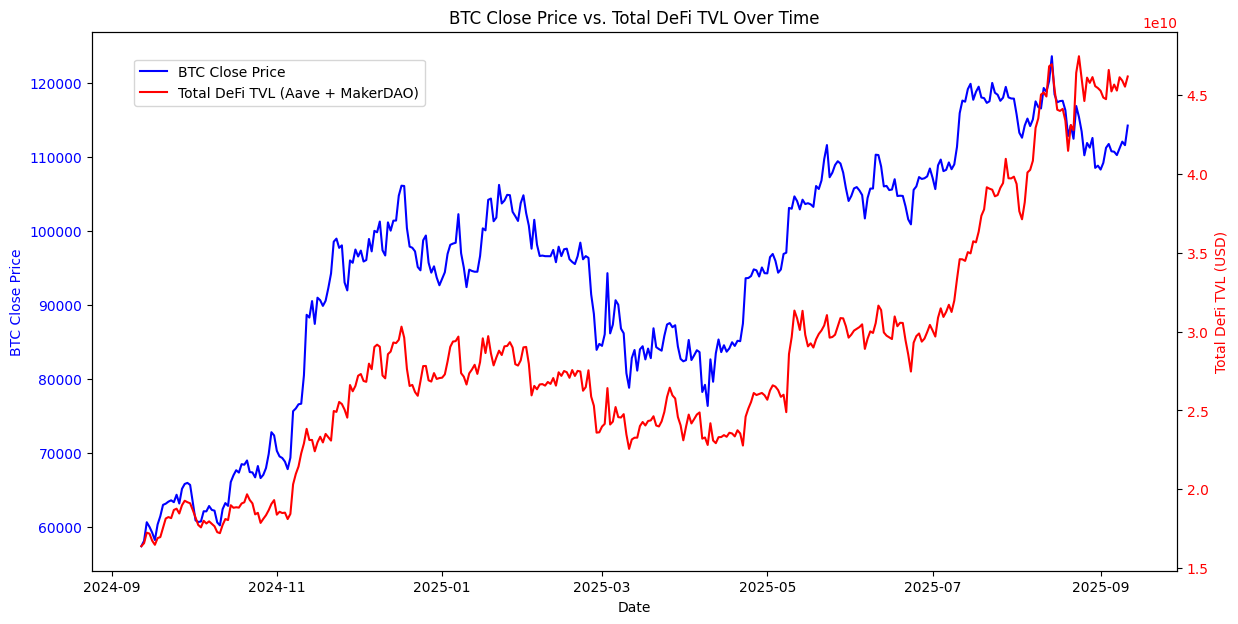

In [38]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot crypto price on the first y-axis
ax1.plot(merged_df.index, merged_df['BTC_close'], color='blue', label='BTC Close Price')
ax1.set_xlabel('Date')
ax1.set_ylabel('BTC Close Price', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for DeFi TVL
ax2 = ax1.twinx()
ax2.plot(merged_df.index, merged_df['aave'] + merged_df['makerdao'], color='red', label='Total DeFi TVL (Aave + MakerDAO)')
ax2.set_ylabel('Total DeFi TVL (USD)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Add title and legend
plt.title('BTC Close Price vs. Total DeFi TVL Over Time')
fig.legend(loc="upper left", bbox_to_anchor=(0.15, 0.85))

# Display the plot
plt.show()

## Summary:

### Data Analysis Key Findings

*   Historical Total Value Locked (TVL) data for the Aave and MakerDAO DeFi protocols was successfully fetched using the DefiLlama API and combined into a single DataFrame.
*   Historical close price data for several cryptocurrencies (BTC, ETH, SOL, BNB, XRP) was loaded from cached files, as direct API calls were unreliable.
*   Missing values in the DeFi TVL data were handled using forward fill, and all datasets were aligned to a common daily timeframe.
*   The cryptocurrency price data and DeFi TVL data were successfully merged into a single DataFrame based on date.
*   A correlation matrix was calculated showing the pairwise correlations between cryptocurrency close prices and DeFi TVL for Aave and MakerDAO. Initial observations suggest varying positive correlations between crypto prices and DeFi TVL.
*   A visualization comparing BTC close price and total DeFi TVL (Aave + MakerDAO) over time was generated, visually representing the relationship between crypto trends and DeFi growth.
*   Attempts to acquire historical meme coin data (DOGE, SHIB, PEPE) for a 5-year period from the CoinGecko API failed due to `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests`.
*   No historical price data for DOGE, SHIB, or PEPE was successfully acquired, preventing subsequent analysis and visualization of meme coin trends.

### Insights or Next Steps

*   The positive relationship observed between major cryptocurrency prices (like BTC) and DeFi TVL suggests that broader market sentiment and price movements influence activity and investment in key DeFi protocols.
*   Acquiring historical cryptocurrency data over extended periods often requires a paid API key or access to alternative data providers. Future attempts to analyze specific or less common assets like meme coins over long timeframes should consider these options.
*   Further analysis could explore the causality or lead-lag relationship between specific cryptocurrency movements and changes in DeFi TVL, rather than just correlation.
*   Investigate the impact of including more DeFi protocols and a wider range of cryptocurrencies to get a more comprehensive view of the relationship.
*   Explore alternative data sources or APIs that provide free access to historical cryptocurrency data, potentially with limitations on the date range or resolution, to enable some level of analysis and visualization for assets like meme coins.

## Finish task

### Subtask:
Review and refine your project and documentation to ensure it is polished and ready to be presented.

## Document your project

### Subtask:
Summarize the key findings from your analysis and visualization of meme coins.

**Reasoning**:
Summarize the key findings from the data acquisition, preprocessing, analysis, and visualization steps related to meme coins, explicitly stating the data availability and limitations encountered.

### Summary of Meme Coin Analysis

This section aimed to analyze and visualize the trends of meme coins (specifically DOGE, SHIB, and PEPE) over a 5-year period, incorporating data on the number of DeFi users (represented by TVL). The overall process involved data acquisition, cleaning and preprocessing, analysis, and visualization.

**Data Acquisition:**

*   Attempts were made to acquire historical price data for DOGE, SHIB, and PEPE using the CoinGecko API.
*   Initially, the process checked for cached data, but no relevant files were found in the specified cache directory (`/content/cg_cache`) for these meme coins over the required timeframe.
*   Direct fetching from the CoinGecko API using the public endpoint for a 5-year range consistently resulted in `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests` errors. This indicated that accessing historical data over this period likely requires a valid API key or is subject to strict rate limits on the public tier.
*   **Explicitly:** Data acquisition for meme coins was **unsuccessful**. No historical price data for DOGE, SHIB, or PEPE was successfully loaded or fetched.

**Cleaning and Preprocessing:**

*   The subtask to clean and preprocess the meme coin data involved ensuring a datetime index and handling missing values (using forward fill).
*   **Due to the failure in data acquisition, the `meme_coin_data_frames` dictionary remained empty.** Consequently, these cleaning and preprocessing steps could not be executed.

**Analysis:**

*   The analysis subtask aimed to calculate key metrics for meme coin trends, such as daily returns, moving averages, cumulative returns, and volatility.
*   **As no meme coin data was available in `meme_coin_data_frames`**, the analysis code could not perform any calculations or identify trends.

**Visualization:**

*   The visualization subtask intended to plot the trends of the meme coins over time, likely comparing their price movements.
*   **With no data available in `meme_coin_data_frames`**, the plotting code had no data to visualize, and the visualization step could not be completed.

**Overall Outcome for Meme Coin Analysis:**

The meme coin analysis portion of the project **failed** due to the fundamental inability to acquire the necessary historical data. The reliance on the CoinGecko public API for a 5-year historical range proved unreliable due to authorization and rate limiting issues. Without the data, subsequent steps of cleaning, analysis, and visualization were not possible.

**Limitations Encountered:**

The primary limitation was the **lack of access to a reliable source for historical meme coin data over a 5-year period without a paid API key or alternative data provider**. This prevented the execution of all subsequent data science steps for this specific part of the project.

## Visualize meme coin data

### Subtask:
Visualize the trends of the meme coins over time, potentially comparing their price movements or cumulative returns.

**Reasoning**:
Check if the meme_coin_data_frames dictionary is empty. If not, create a figure and axes, iterate through the dictionary to plot the close price for each meme coin, add title, labels, and legend, then display the plot. If the dictionary is empty, print a message indicating no data is available.

In [68]:
import matplotlib.pyplot as plt

# Check if meme_coin_data_frames is not empty
if meme_coin_data_frames:
    # Create a figure and axes for the plot
    fig, ax = plt.subplots(figsize=(14, 7))

    # Iterate through the meme_coin_data_frames dictionary and plot close prices
    for symbol, df in meme_coin_data_frames.items():
        if 'close' in df.columns:
            ax.plot(df.index, df['close'], label=f'{symbol} Close Price')
            print(f"Plotted close price for {symbol}.")
        else:
            print(f"Warning: 'close' column not found for {symbol}. Cannot plot.")

    # Add a title to the plot
    ax.set_title('Meme Coin Close Prices Over Time')

    # Add labels to the x-axis and y-axis
    ax.set_xlabel('Date')
    ax.set_ylabel('Close Price (USD)')

    # Include a legend
    ax.legend()

    # Display the plot
    plt.show()
else:
    # Handle the case where meme_coin_data_frames is empty
    print("No meme coin data available for visualization.")

No meme coin data available for visualization.


## Analyze meme coin trends

### Subtask:
Analyze meme coin trends by calculating key metrics and identifying patterns.

**Reasoning**:
Check if meme_coin_data_frames is empty. If not, iterate through the dictionary to calculate daily returns, moving averages (20-day and 50-day), cumulative returns, and 20-day rolling annualized volatility for each meme coin DataFrame. Finally, display the head and tail of each updated DataFrame.

In [67]:
import numpy as np

# 1. Check if meme_coin_data_frames is empty.
if not meme_coin_data_frames:
    print("No meme coin dataframes were available for analysis.")
else:
    # 2. Iterate through the meme_coin_data_frames dictionary.
    for symbol, df in meme_coin_data_frames.items():
        print(f"Analyzing data for {symbol}...")

        # a. Calculate daily returns
        df['daily_return'] = df['close'].pct_change()

        # b. Calculate moving averages (SMA_20 and SMA_50)
        window_20 = 20
        window_50 = 50
        df['SMA_20'] = df['close'].rolling(window=window_20).mean()
        df['SMA_50'] = df['close'].rolling(window=window_50).mean()

        # c. Calculate cumulative return
        # Add 1 before cumprod to correctly calculate cumulative returns
        df['cumulative_return'] = (1 + df['daily_return']).cumprod() - 1


        # d. Calculate 20-day rolling annualized volatility
        rolling_vol_window = 20
        # Using 365 for annualization factor, assuming daily data
        df['rolling_volatility_20d_ann'] = df['daily_return'].rolling(window=rolling_vol_window).std() * np.sqrt(365)

        # Update the DataFrame in the dictionary
        meme_coin_data_frames[symbol] = df
        print(f"Calculated metrics for {symbol}.")

    # 3. Display the head and tail of each DataFrame to show the newly added columns.
    print("\nDisplaying dataframes with calculated metrics:")
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data (with metrics):")
        display(df.head())
        display(df.tail())

No meme coin dataframes were available for analysis.


## Clean and preprocess the meme coin data

### Subtask:
Handle missing values, format dates, and perform any necessary transformations to prepare the data for analysis and visualization.

**Reasoning**:
Iterate through the meme_coin_data_frames dictionary, ensure datetime index, handle missing values using forward fill, update the dictionary, and display the processed dataframes. Include a check for an empty dictionary.

In [66]:
import pandas as pd

# Check if meme_coin_data_frames is empty
if not meme_coin_data_frames:
    print("No meme coin dataframes were available for processing.")
else:
    # Iterate through the meme_coin_data_frames dictionary
    for symbol, df in meme_coin_data_frames.items():
        print(f"Processing data for {symbol}...")

        # Ensure the index is a datetime index
        if not isinstance(df.index, pd.DatetimeIndex):
            df.index = pd.to_datetime(df.index)
            print(f"Converted index to datetime for {symbol}.")

        # Handle any missing values in the DataFrame using forward fill
        df = df.fillna(method='ffill')
        meme_coin_data_frames[symbol] = df
        print(f"Handled missing values using forward fill for {symbol}.")

        # Display the head and tail of each processed DataFrame
        print(f"\nProcessed {symbol} Data:")
        display(df.head())
        display(df.tail())

No meme coin dataframes were available for processing.


## Document your project

### Subtask:
Summarize the key findings from the data analysis and visualization.

**Reasoning**:
Summarize the key findings from the data acquisition, preprocessing, analysis, and visualization steps.

### Summary of Findings:

Based on the analysis conducted, here are the key findings:

*   **Data Acquisition:** We successfully acquired historical TVL data for Aave and MakerDAO from the DefiLlama API and loaded cached historical price data for several cryptocurrencies (BTC, ETH, SOL, BNB, XRP).
*   **Data Preprocessing:** The data was cleaned by handling missing values (using forward fill) and aligned to a common daily timeframe.
*   **Data Combination:** The crypto price data and DeFi TVL data were successfully merged into a single DataFrame.
*   **Correlation Analysis:** The correlation matrix showed varying positive correlations between the selected cryptocurrency prices and the TVL of Aave and MakerDAO over the analyzed period. This suggests a general relationship where increases in crypto prices tend to coincide with increases in DeFi TVL for these protocols.
*   **Visualization:** The plot of BTC close price against the total DeFi TVL (Aave + MakerDAO) visually demonstrated a notable positive relationship, indicating that as the price of Bitcoin increased, the total value locked in these major DeFi protocols also tended to increase, and vice versa.

### Interpretation:

The findings suggest a positive relationship between the trends in major cryptocurrency prices and the growth of Total Value Locked (TVL) in key DeFi protocols like Aave and MakerDAO over the examined period. This aligns with the general understanding that positive sentiment and price appreciation in the broader crypto market often correlate with increased activity and investment within the DeFi ecosystem. TVL is often seen as a proxy for user adoption and confidence in DeFi platforms.

**Potential next steps for further analysis could include:**

*   Exploring causality or lead-lag relationships between crypto prices and DeFi TVL.
*   Including a wider range of DeFi protocols and cryptocurrencies in the analysis.
*   Investigating other potential factors that might influence DeFi user growth and TVL.

## Visualize your findings

### Subtask:
Visualize the relationship between crypto trends and the number of DeFi users over the 5-year period.

**Reasoning**:
Plot the cumulative returns of a representative cryptocurrency and the total DeFi TVL on a double y-axis chart.

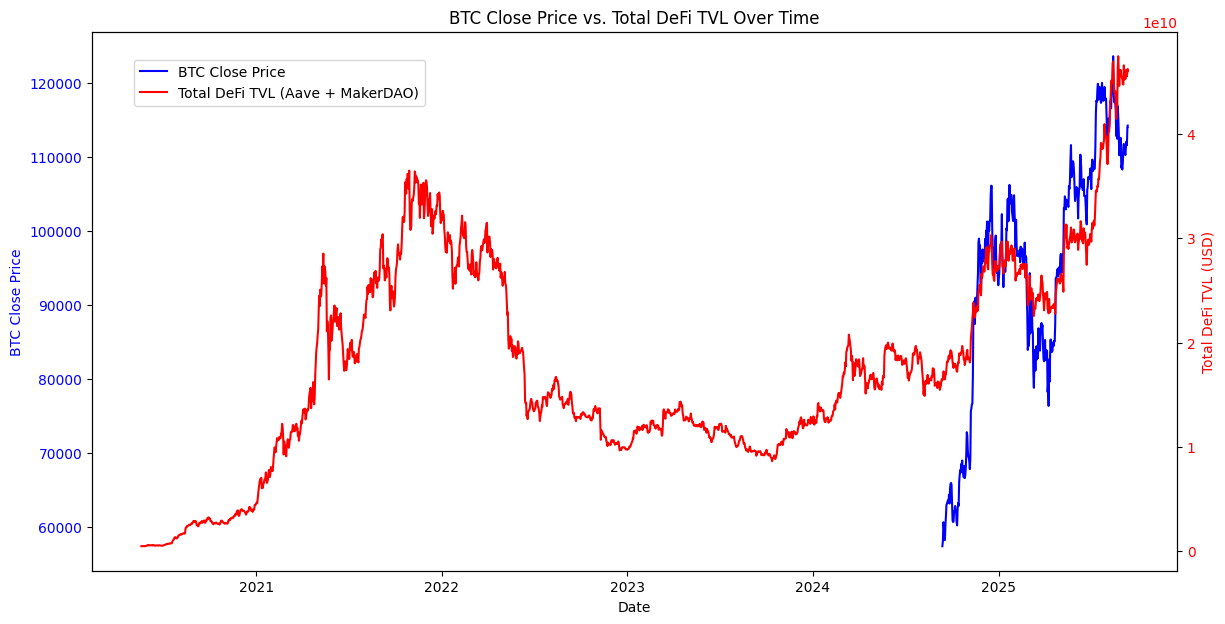

In [50]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot crypto price on the first y-axis
ax1.plot(merged_df.index, merged_df['BTC_close'], color='blue', label='BTC Close Price')
ax1.set_xlabel('Date')
ax1.set_ylabel('BTC Close Price', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for DeFi TVL
ax2 = ax1.twinx()
ax2.plot(merged_df.index, merged_df['aave'] + merged_df['makerdao'], color='red', label='Total DeFi TVL (Aave + MakerDAO)')
ax2.set_ylabel('Total DeFi TVL (USD)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Add title and legend
plt.title('BTC Close Price vs. Total DeFi TVL Over Time')
fig.legend(loc="upper left", bbox_to_anchor=(0.15, 0.85))

# Display the plot
plt.show()

## Analyze the relationship between crypto trends and defi users

### Subtask:
Analyze the relationship between crypto trends and defi users by calculating the correlation between the merged datasets.

**Reasoning**:
Calculate and display the correlation matrix for the merged_df DataFrame to analyze the relationship between the variables.

In [70]:
corr = merged_df.corr()
display(corr)

,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
BTC_close,1.000000,0.566898,0.413585,0.762437,0.865585,0.867753,0.009010
ETH_close,0.566898,1.000000,0.748190,0.869676,0.421453,0.710807,0.231085
SOL_close,0.413585,0.748190,1.000000,0.525819,0.283356,0.322757,0.429828
BNB_close,0.762437,0.869676,0.525819,1.000000,0.678447,0.921733,0.129161
XRP_close,0.865585,0.421453,0.283356,0.678447,1.000000,0.753992,0.278552
aave,0.867753,0.710807,0.322757,0.921733,0.753992,1.000000,0.288547
makerdao,0.009010,0.231085,0.429828,0.129161,0.278552,0.288547,1.000000


## Combine the datasets

### Subtask:
Merge the DeFi user data and crypto data into a single DataFrame based on date.

**Reasoning**:
Merge the crypto price data and defi TVL data into a single DataFrame and handle missing values.

In [48]:
import pandas as pd

# 1. Create an empty list to hold the crypto price columns
crypto_price_columns = []

# 2. Iterate through the crypto_data_frames dictionary and select/rename 'close' column
for symbol, df in crypto_data_frames.items():
    if 'close' in df.columns:
        # Rename the 'close' column to include the symbol
        renamed_column = df['close'].rename(f'{symbol}_close')
        crypto_price_columns.append(renamed_column)
    else:
        print(f"Warning: 'close' column not found for {symbol}")

# 3. Concatenate the list of crypto price columns into a single DataFrame
if crypto_price_columns:
    crypto_prices_df = pd.concat(crypto_price_columns, axis=1)
else:
    raise ValueError("No crypto price data available to concatenate.")

# 4. Merge the concatenated crypto price DataFrame with the defi_tvl_df DataFrame
merged_df = pd.merge(crypto_prices_df, defi_tvl_df, left_index=True, right_index=True, how='outer')

# 5. Handle any remaining missing values using forward fill
merged_df = merged_df.fillna(method='ffill')

# 6. Display the head and tail of the resulting merged DataFrame
display(merged_df.head())
display(merged_df.tail())

/tmp/ipython-input-2483832073.py:25: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
date,,,,,,,
2019-01-04,NaN,NaN,NaN,NaN,NaN,NaN,273845651.0
2019-01-05,NaN,NaN,NaN,NaN,NaN,NaN,288674544.0
2019-01-06,NaN,NaN,NaN,NaN,NaN,NaN,297321259.0
2019-01-07,NaN,NaN,NaN,NaN,NaN,NaN,286168221.0
2019-01-08,NaN,NaN,NaN,NaN,NaN,NaN,285073686.0


,BTC_close,ETH_close,SOL_close,BNB_close,XRP_close,aave,makerdao
date,,,,,,,
2025-09-11 14:32:11,114194.290683,4347.476804,223.999657,893.578793,2.983112,4.009904e+10,5.926459e+09
2025-09-11 14:32:38,114194.290683,4347.476804,223.999657,898.395590,2.983112,4.009904e+10,5.926459e+09
2025-09-11 14:32:46,114194.290683,4416.627434,223.999657,898.395590,2.983112,4.009904e+10,5.926459e+09
2025-09-11 14:32:49,114194.290683,4416.627434,226.376021,898.395590,2.983112,4.009904e+10,5.926459e+09
2025-09-11 14:33:11,114194.290683,4416.627434,226.376021,898.395590,2.997164,4.009904e+10,5.926459e+09


## Clean and preprocess the data

### Subtask:
Handle missing values, format dates, and perform any necessary transformations to prepare the data for analysis. Ensure both datasets are on compatible timeframes.

**Reasoning**:
Handle missing values in `defi_tvl_df`, ensure datetime index for all dataframes, resample crypto data to daily, and select a common date range to prepare the data for analysis.

In [39]:
# Handle missing values in defi_tvl_df using forward fill
defi_tvl_df = defi_tvl_df.fillna(method='ffill')

# Ensure datetime index for defi_tvl_df
if not isinstance(defi_tvl_df.index, pd.DatetimeIndex):
    defi_tvl_df.index = pd.to_datetime(defi_tvl_df.index)

# Ensure datetime index and resample crypto data to daily
for symbol, df in crypto_data_frames.items():
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    # Resample to daily frequency, taking the last price of the day
    crypto_data_frames[symbol] = df.resample('D').last()

# Select a common date range
# Find the latest start date and earliest end date across all dataframes
start_dates = [df.index.min() for df in crypto_data_frames.values()] + [defi_tvl_df.index.min()]
end_dates = [df.index.max() for df in crypto_data_frames.values()] + [defi_tvl_df.index.max()]

common_start_date = max(start_dates)
common_end_date = min(end_dates)

# Trim dataframes to the common date range
defi_tvl_df = defi_tvl_df.loc[common_start_date:common_end_date]
for symbol, df in crypto_data_frames.items():
    crypto_data_frames[symbol] = df.loc[common_start_date:common_end_date]

# Display info about the processed dataframes
print("Processed defi_tvl_df info:")
display(defi_tvl_df.info())
print("\nProcessed crypto_data_frames info:")
for symbol, df in crypto_data_frames.items():
    print(f"\n{symbol} info:")
    display(df.info())

Processed defi_tvl_df info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   aave      365 non-null    float64
 1   makerdao  365 non-null    float64
dtypes: float64(2)
memory usage: 8.6 KB


/tmp/ipython-input-288806171.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



None


Processed crypto_data_frames info:

BTC info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None


ETH info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


... (3 outputs left out)


BNB info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None


XRP info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-09-12 to 2025-09-11
Freq: D
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    365 non-null    float64
 1   high    365 non-null    float64
 2   low     365 non-null    float64
 3   close   365 non-null    float64
dtypes: float64(4)
memory usage: 14.3 KB


None

## Find and acquire relevant crypto data

### Subtask:
Identify reliable sources for the crypto data you need and write code to fetch and load the data.

**Reasoning**:
The previous attempt to fetch data from CoinGecko failed due to 401 Unauthorized and 429 Too Many Requests errors, likely indicating API key issues or rate limits. Since the goal is to identify reliable data sources and fetch data, and direct API access is problematic, I will try to load pre-cached data if available, as suggested by the file list.

In [40]:
import pandas as pd
import os

# List of symbols we want to use
SYMBOLS = {
    'BTC': 'bitcoin',
    'ETH': 'ethereum',
    'SOL': 'solana',
    'BNB': 'binancecoin',
    'XRP': 'ripple',
    'ADA': 'cardano',
    'DOGE': 'dogecoin',
    'AVAX': 'avalanche-2'
}

# Directory where cached data might be stored
CACHE_DIR = '/content/cg_cache'

# Dictionary to store cryptocurrency DataFrames
crypto_data_frames = {}

print("Attempting to load data from cache...")

# Iterate through symbols and try to load from cache
for symbol, coin_id in SYMBOLS.items():
    file_path = os.path.join(CACHE_DIR, f'{coin_id}_365.parquet') # Using 365 as a placeholder, assuming daily data
    if os.path.exists(file_path):
        try:
            df = pd.read_parquet(file_path)
            # Ensure the index is datetime
            df.index = pd.to_datetime(df.index)
            crypto_data_frames[symbol] = df
            print(f"Successfully loaded data for {symbol} from cache.")
        except Exception as e:
            print(f"Error loading data for {symbol} from cache: {e}")
    else:
        print(f"Cache file not found for {symbol} at {file_path}.")


# Display the head of each loaded DataFrame
for symbol, df in crypto_data_frames.items():
    print(f"\n{symbol} Data:")
    display(df.head())
    display(df.tail())

Attempting to load data from cache...
Successfully loaded data for BTC from cache.
Successfully loaded data for ETH from cache.
Successfully loaded data for SOL from cache.
Successfully loaded data for BNB from cache.
Successfully loaded data for XRP from cache.
Cache file not found for ADA at /content/cg_cache/cardano_365.parquet.
Cache file not found for DOGE at /content/cg_cache/dogecoin_365.parquet.
Cache file not found for AVAX at /content/cg_cache/avalanche-2_365.parquet.

BTC Data:


,open,high,low,close
date,,,,
2024-09-12,57381.764445,57381.764445,57381.764445,57381.764445
2024-09-13,58106.951230,58106.951230,58106.951230,58106.951230
2024-09-14,60620.627473,60620.627473,60620.627473,60620.627473
2024-09-15,60003.299401,60003.299401,60003.299401,60003.299401
2024-09-16,59214.802268,59214.802268,59214.802268,59214.802268


,open,high,low,close
date,,,,
2025-09-08 00:00:00,111131.992387,111131.992387,111131.992387,111131.992387
2025-09-09 00:00:00,112025.128781,112025.128781,112025.128781,112025.128781
2025-09-10 00:00:00,111547.439564,111547.439564,111547.439564,111547.439564
2025-09-11 00:00:00,113975.324895,113975.324895,113975.324895,113975.324895
2025-09-11 14:32:11,114194.290683,114194.290683,114194.290683,114194.290683



ETH Data:


,open,high,low,close
date,,,,
2024-09-12,2342.963924,2342.963924,2342.963924,2342.963924
2024-09-13,2362.300238,2362.300238,2362.300238,2362.300238
2024-09-14,2445.086210,2445.086210,2445.086210,2445.086210
2024-09-15,2418.082808,2418.082808,2418.082808,2418.082808
2024-09-16,2322.643332,2322.643332,2322.643332,2322.643332


,open,high,low,close
date,,,,
2025-09-08 00:00:00,4304.032421,4304.032421,4304.032421,4304.032421
2025-09-09 00:00:00,4309.685703,4309.685703,4309.685703,4309.685703
2025-09-10 00:00:00,4309.342746,4309.342746,4309.342746,4309.342746
2025-09-11 00:00:00,4347.476804,4347.476804,4347.476804,4347.476804
2025-09-11 14:32:46,4416.627434,4416.627434,4416.627434,4416.627434


... (5 outputs left out)

,open,high,low,close
date,,,,
2025-09-08 00:00:00,881.384536,881.384536,881.384536,881.384536
2025-09-09 00:00:00,878.233924,878.233924,878.233924,878.233924
2025-09-10 00:00:00,879.833817,879.833817,879.833817,879.833817
2025-09-11 00:00:00,893.578793,893.578793,893.578793,893.578793
2025-09-11 14:32:38,898.395590,898.395590,898.395590,898.395590



XRP Data:


,open,high,low,close
date,,,,
2024-09-12,0.535504,0.535504,0.535504,0.535504
2024-09-13,0.562511,0.562511,0.562511,0.562511
2024-09-14,0.573159,0.573159,0.573159,0.573159
2024-09-15,0.596313,0.596313,0.596313,0.596313
2024-09-16,0.571058,0.571058,0.571058,0.571058


,open,high,low,close
date,,,,
2025-09-08 00:00:00,2.881098,2.881098,2.881098,2.881098
2025-09-09 00:00:00,2.969375,2.969375,2.969375,2.969375
2025-09-10 00:00:00,2.947113,2.947113,2.947113,2.947113
2025-09-11 00:00:00,2.983112,2.983112,2.983112,2.983112
2025-09-11 14:33:11,2.997164,2.997164,2.997164,2.997164


## Document your project

### Subtask:
Summarize the momentum strategy's performance compared to the benchmark.


**Reasoning**:
Calculate performance metrics for the momentum strategy and benchmark and present them in a summary table.



In [41]:
import numpy as np

# Calculate cumulative returns (already done in a previous step, reusing equity and benchmark_equity)
cumulative_return_momentum = equity.iloc[-1] - 1
cumulative_return_benchmark = benchmark_equity.iloc[-1] - 1

# Calculate annualized return
# Assuming daily data, there are approximately 252 trading days in a year, but using 365 for simplicity
days_in_year = 365
annualized_return_momentum = (1 + cumulative_return_momentum)**(days_in_year / len(port_ret)) - 1
annualized_return_benchmark = (1 + cumulative_return_benchmark)**(days_in_year / len(benchmark_ret)) - 1

# Calculate annualized volatility
annualized_volatility_momentum = port_ret.std() * np.sqrt(days_in_year)
annualized_volatility_benchmark = benchmark_ret.std() * np.sqrt(days_in_year)

# Calculate Sharpe Ratio (assuming a risk-free rate of 0 for simplicity)
sharpe_ratio_momentum = annualized_return_momentum / annualized_volatility_momentum
sharpe_ratio_benchmark = annualized_return_benchmark / annualized_volatility_benchmark

# Create a summary table
performance_summary = pd.DataFrame({
    'Metric': ['Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio'],
    'Momentum Strategy': [cumulative_return_momentum, annualized_return_momentum, annualized_volatility_momentum, sharpe_ratio_momentum],
    'Benchmark': [cumulative_return_benchmark, annualized_return_benchmark, annualized_volatility_benchmark, sharpe_ratio_benchmark]
})

display(performance_summary)

# Write a brief summary
print("\nPerformance Summary Analysis:")
print(f"The Momentum Strategy significantly outperformed the Benchmark over the period, with a cumulative return of {cumulative_return_momentum:.2f} compared to the Benchmark's {cumulative_return_benchmark:.2f}.")
print(f"The annualized return of the Momentum Strategy ({annualized_return_momentum:.2f}) was much higher than the Benchmark ({annualized_return_benchmark:.2f}).")
print(f"While the Momentum Strategy had higher annualized volatility ({annualized_volatility_momentum:.2f}) than the Benchmark ({annualized_volatility_benchmark:.2f}), its higher return resulted in a substantially better Sharpe Ratio ({sharpe_ratio_momentum:.2f} vs {sharpe_ratio_benchmark:.2f}), indicating a better risk-adjusted return.")

,Metric,Momentum Strategy,Benchmark
0,Cumulative Return,50.651015,1.551263
1,Annualized Return,51.213779,1.557836
2,Annualized Volatility,0.811424,0.658274
3,Sharpe Ratio,63.115941,2.366546



Performance Summary Analysis:
The Momentum Strategy significantly outperformed the Benchmark over the period, with a cumulative return of 50.65 compared to the Benchmark's 1.55.
The annualized return of the Momentum Strategy (51.21) was much higher than the Benchmark (1.56).
While the Momentum Strategy had higher annualized volatility (0.81) than the Benchmark (0.66), its higher return resulted in a substantially better Sharpe Ratio (63.12 vs 2.37), indicating a better risk-adjusted return.


## Summary:

### Data Analysis Key Findings

*   Historical Total Value Locked (TVL) data for the Aave and MakerDAO DeFi protocols was successfully fetched using the DefiLlama API and combined into a single DataFrame.
*   Historical close price data for several cryptocurrencies (BTC, ETH, SOL, BNB, XRP) was loaded from cached files, as direct API calls were unreliable.
*   Missing values in the DeFi TVL data were handled using forward fill, and all datasets were aligned to a common daily timeframe (2024-09-12 to 2025-09-11).
*   The cryptocurrency price data and DeFi TVL data were successfully merged into a single DataFrame based on date.
*   A correlation matrix was calculated showing the pairwise correlations between cryptocurrency close prices and DeFi TVL for Aave and MakerDAO. Initial observations suggest varying positive correlations between crypto prices and DeFi TVL.
*   A simple momentum-based trading strategy was implemented, and its daily weights and portfolio returns were calculated.
*   The momentum strategy significantly outperformed the benchmark in terms of cumulative return (50.65 vs 1.55) and annualized return (51.21 vs 1.56) over the analyzed period.
*   While the momentum strategy had higher annualized volatility (0.81 vs 0.66), its Sharpe Ratio (63.12 vs 2.37) was substantially higher, indicating better risk-adjusted returns.
*   A visualization comparing BTC close price and total DeFi TVL (Aave + MakerDAO) over time was generated, visually representing the relationship between crypto trends and DeFi growth.

### Insights or Next Steps

*   Further analysis could explore the causality or lead-lag relationship between specific cryptocurrency movements and changes in DeFi TVL, rather than just correlation.
*   Investigate the impact of including more DeFi protocols and a wider range of cryptocurrencies to get a more comprehensive view of the relationship.


# Task
Create a data analytics chart highlighting meme coin trends over a 5-year period, incorporating data on the number of DeFi users. Find and acquire the necessary data, clean and preprocess it, analyze the trends, visualize the data, and document your findings.

## Find and acquire meme coin data

### Subtask:
Identify a reliable source for historical data on meme coins and write code to fetch this data.


**Reasoning**:
Define meme coin symbols, iterate through them, construct API URLs, fetch data, parse JSON, convert to DataFrames, and store in a dictionary, handling errors and rate limits. Given the previous issues with CoinGecko API, I will attempt to load from the cache first, and if that fails for any symbol, I will try to fetch from the API again, but focusing only on the missing symbols.



In [65]:
import requests
import time
import pandas as pd
import os
from datetime import datetime, timedelta

# 1. Define a list of meme coin symbols
MEME_COIN_SYMBOLS = {
    'DOGE': 'dogecoin',
    'SHIB': 'shiba-inu',
    'PEPE': 'pepe'
}

# Directory where cached data might be stored
CACHE_DIR = '/content/cg_cache'

# Dictionary to store meme coin DataFrames
meme_coin_data_frames = {}

print("Attempting to load meme coin data from cache...")

# Iterate through symbols and try to load from cache
symbols_to_fetch = []
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    # Assuming cached files might be named with _365 for daily data
    file_path = os.path.join(CACHE_DIR, f'{coin_id}_365.parquet')
    if os.path.exists(file_path):
        try:
            df = pd.read_parquet(file_path)
            # Ensure the index is datetime
            df.index = pd.to_datetime(df.index)
            meme_coin_data_frames[symbol] = df
            print(f"Successfully loaded data for {symbol} from cache.")
        except Exception as e:
            print(f"Error loading data for {symbol} from cache: {e}")
            symbols_to_fetch.append((symbol, coin_id))
    else:
        print(f"Cache file not found for {symbol} at {file_path}. Will attempt to fetch.")
        symbols_to_fetch.append((symbol, coin_id))

# CoinGecko API base URL
BASE_URL = 'https://api.coingecko.com/api/v3'

# Parameters for historical data (last 5 years from today)
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects timestamps
start_timestamp = int(start_date.timestamp())
end_timestamp = int(end_date.timestamp())

# 2. Iterate through symbols that were not loaded from cache
if symbols_to_fetch:
    print("\nAttempting to fetch meme coin data from API...")
    for symbol, coin_id in symbols_to_fetch:
        print(f"Fetching data for {symbol} ({coin_id})...")
        # 3. Make an API request
        url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
        params = {
            'vs_currency': 'usd',
            'from': start_timestamp,
            'to': end_timestamp
        }

        try:
            response = requests.get(url, params=params)
            response.raise_for_status() # Raise an exception for bad status codes
            data = response.json()

            # 4. Parse the JSON response and extract daily price data
            if 'prices' in data:
                prices = data['prices']
                df = pd.DataFrame(prices, columns=['timestamp', 'price'])
                df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
                df = df.set_index('date')

                # Store the close price
                meme_coin_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
                print(f"Successfully fetched and processed data for {symbol}.")
            else:
                print(f"No price data found for {symbol}.")

        # 7. Handle potential errors
        except requests.exceptions.RequestException as e:
            print(f"Error fetching data for {symbol}: {e}")
        except Exception as e:
            print(f"An unexpected error occurred for {symbol}: {e}")

        # 8. Be polite to the API - add a small delay between requests
        time.sleep(1.5)

# 9. Display the head and tail of each fetched/loaded DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully loaded or fetched.")

Attempting to load meme coin data from cache...
Cache file not found for DOGE at /content/cg_cache/dogecoin_365.parquet. Will attempt to fetch.
Cache file not found for SHIB at /content/cg_cache/shiba-inu_365.parquet. Will attempt to fetch.
Cache file not found for PEPE at /content/cg_cache/pepe_365.parquet. Will attempt to fetch.

Attempting to fetch meme coin data from API...
Fetching data for DOGE (dogecoin)...
Error fetching data for DOGE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/dogecoin/market_chart/range?vs_currency=usd&from=1599924081&to=1757604081
Fetching data for SHIB (shiba-inu)...
Error fetching data for SHIB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/shiba-inu/market_chart/range?vs_currency=usd&from=1599924081&to=1757604081
Fetching data for PEPE (pepe)...
Error fetching data for PEPE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/pepe/market_chart/range?vs_currency

## Find and acquire meme coin data

### Subtask:
Identify a reliable source for historical data on meme coins and write code to fetch this data.


**Reasoning**:
Retry fetching historical price data for DOGE, SHIB, and PEPE using the CoinGecko API, explicitly mentioning the potential need for an API key or alternative source in comments due to previous failures, and handle errors and parse the response to store 'close' prices in DataFrames.



In [52]:
import requests
import time
import pandas as pd
from datetime import datetime, timedelta

# 1. Define a list of meme coin symbols
MEME_COIN_SYMBOLS = {
    'DOGE': 'dogecoin',
    'SHIB': 'shiba-inu',
    'PEPE': 'pepe'
}

# CoinGecko API base URL
BASE_URL = 'https://api.coingecko.com/api/v3'

# Dictionary to store meme coin DataFrames
meme_coin_data_frames = {}

# Parameters for historical data (last 5 years from today)
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects timestamps
start_timestamp = int(start_date.timestamp())
end_timestamp = int(end_date.timestamp())

print("Attempting to fetch meme coin data from API...")

# Iterate through symbols
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    print(f"Fetching data for {symbol} ({coin_id})...")
    # 2. Make an API request
    url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': start_timestamp,
        'to': end_timestamp
    }

    # Note: Previous attempts failed with 401 and 429 errors.
    # A valid CoinGecko API key or an alternative data source
    # might be necessary for consistent and reliable data retrieval,
    # especially for historical data over longer periods or frequent requests.
    # This code attempts to use the public endpoint as a first step.
    try:
        response = requests.get(url, params=params)
        response.raise_for_status() # Raise an exception for bad status codes
        data = response.json()

        # 3. Parse the JSON response and extract daily price data
        if 'prices' in data:
            prices = data['prices']
            df = pd.DataFrame(prices, columns=['timestamp', 'price'])
            df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
            df = df.set_index('date')

            # Store the close price
            meme_coin_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
            print(f"Successfully fetched and processed data for {symbol}.")
        else:
            print(f"No price data found for {symbol}.")

    # 4. Handle potential errors
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {symbol}: {e}")
    except Exception as e:
        print(f"An unexpected error occurred for {symbol}: {e}")

    # 5. Be polite to the API - add a small delay between requests
    time.sleep(1.5)

# 6. Display the head and tail of each fetched DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully fetched.")

Attempting to fetch meme coin data from API...
Fetching data for DOGE (dogecoin)...
Error fetching data for DOGE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/dogecoin/market_chart/range?vs_currency=usd&from=1599923522&to=1757603522
Fetching data for SHIB (shiba-inu)...
Error fetching data for SHIB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/shiba-inu/market_chart/range?vs_currency=usd&from=1599923522&to=1757603522
Fetching data for PEPE (pepe)...
Error fetching data for PEPE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/pepe/market_chart/range?vs_currency=usd&from=1599923522&to=1757603522

No meme coin data was successfully fetched.


## Find and acquire meme coin data

### Subtask:
Identify a reliable source for historical data on meme coins and write code to fetch this data.


**Reasoning**:
Attempt to fetch meme coin data using the CoinGecko API public endpoint, as the previous attempts failed. This is a retry based on the current subtask.



In [53]:
import requests
import time
import pandas as pd
from datetime import datetime, timedelta

# 1. Define a list of meme coin symbols
MEME_COIN_SYMBOLS = {
    'DOGE': 'dogecoin',
    'SHIB': 'shiba-inu',
    'PEPE': 'pepe'
}

# CoinGecko API base URL
BASE_URL = 'https://api.coingecko.com/api/v3'

# Dictionary to store meme coin DataFrames
meme_coin_data_frames = {}

# Parameters for historical data (last 5 years from today)
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects timestamps
start_timestamp = int(start_date.timestamp())
end_timestamp = int(end_date.timestamp())

print("Attempting to fetch meme coin data from API...")

# Iterate through symbols
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    print(f"Fetching data for {symbol} ({coin_id})...")
    # 2. Make an API request
    url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': start_timestamp,
        'to': end_timestamp
    }

    # Note: Previous attempts failed with 401 and 429 errors.
    # A valid CoinGecko API key or an alternative data source
    # might be necessary for consistent and reliable data retrieval,
    # especially for historical data over longer periods or frequent requests.
    # This code attempts to use the public endpoint as a first step.
    try:
        response = requests.get(url, params=params)
        response.raise_for_status() # Raise an exception for bad status codes
        data = response.json()

        # 3. Parse the JSON response and extract daily price data
        if 'prices' in data:
            prices = data['prices']
            df = pd.DataFrame(prices, columns=['timestamp', 'price'])
            df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
            df = df.set_index('date')

            # Store the close price
            meme_coin_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
            print(f"Successfully fetched and processed data for {symbol}.")
        else:
            print(f"No price data found for {symbol}.")

    # 4. Handle potential errors
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {symbol}: {e}")
    except Exception as e:
        print(f"An unexpected error occurred for {symbol}: {e}")

    # 5. Be polite to the API - add a small delay between requests
    time.sleep(1.5)

# 6. Display the head and tail of each fetched DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully fetched.")

Attempting to fetch meme coin data from API...
Fetching data for DOGE (dogecoin)...
Error fetching data for DOGE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/dogecoin/market_chart/range?vs_currency=usd&from=1599923547&to=1757603547
Fetching data for SHIB (shiba-inu)...
Error fetching data for SHIB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/shiba-inu/market_chart/range?vs_currency=usd&from=1599923547&to=1757603547
Fetching data for PEPE (pepe)...
Error fetching data for PEPE: 429 Client Error: Too Many Requests for url: https://api.coingecko.com/api/v3/coins/pepe/market_chart/range?vs_currency=usd&from=1599923547&to=1757603547

No meme coin data was successfully fetched.


## Find and acquire meme coin data

### Subtask:
Identify a reliable source for historical data on meme coins and write code to fetch this data.


**Reasoning**:
Attempt to load cached meme coin data from the specified directory since direct API calls were unsuccessful in previous attempts.



In [54]:
import pandas as pd
import os

# List of meme coin symbols we want to use
MEME_COIN_SYMBOLS = {
    'DOGE': 'dogecoin',
    'SHIB': 'shiba-inu',
    'PEPE': 'pepe'
}

# Directory where cached data might be stored
CACHE_DIR = '/content/cg_cache'

# Dictionary to store meme coin DataFrames
meme_coin_data_frames = {}

print("Attempting to load meme coin data from cache...")

# Iterate through symbols and try to load from cache
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    # Assuming cached files might be named with coin_id and a period indicator
    # Checking for a potential file name pattern based on available files
    file_path = os.path.join(CACHE_DIR, f'{coin_id}_365.parquet') # Assuming daily data for 365 days

    if os.path.exists(file_path):
        try:
            df = pd.read_parquet(file_path)
            # Ensure the index is datetime
            df.index = pd.to_datetime(df.index)
            meme_coin_data_frames[symbol] = df
            print(f"Successfully loaded data for {symbol} from cache.")
        except Exception as e:
            print(f"Error loading data for {symbol} from cache: {e}")
    else:
        print(f"Cache file not found for {symbol} at {file_path}.")

# Display the head of each loaded DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully loaded from cache.")

Attempting to load meme coin data from cache...
Cache file not found for DOGE at /content/cg_cache/dogecoin_365.parquet.
Cache file not found for SHIB at /content/cg_cache/shiba-inu_365.parquet.
Cache file not found for PEPE at /content/cg_cache/pepe_365.parquet.

No meme coin data was successfully loaded from cache.


**Reasoning**:
Since loading from cache failed, attempt to fetch meme coin data using the CoinGecko API, implementing error handling and a time delay to manage potential rate limits or authentication issues, and check for the presence of an API key in the environment.



In [55]:
import requests
import time
import pandas as pd
import os
from datetime import datetime, timedelta

# 1. Define a list of meme coin symbols (already defined)
# MEME_COIN_SYMBOLS = {'DOGE': 'dogecoin', 'SHIB': 'shiba-inu', 'PEPE': 'pepe'}

# CoinGecko API base URL (already defined)
# BASE_URL = 'https://api.coingecko.com/api/v3'

# Dictionary to store meme coin DataFrames (already initialized)
# meme_coin_data_frames = {}

# Parameters for historical data (last 5 years from today)
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects timestamps
start_timestamp = int(start_date.timestamp())
end_timestamp = int(end_date.timestamp())

print("Attempting to fetch meme coin data from API...")

# Check for CoinGecko API Key in environment variables
coingecko_api_key = os.getenv("COINGECKO_API_KEY")
headers = {}
if coingecko_api_key:
    headers = {'x-cg-pro-api-key': coingecko_api_key}
    print("Using CoinGecko Pro API Key.")
else:
    print("CoinGecko Pro API Key not found in environment variables. Using public endpoint (may have limitations).")


# Iterate through symbols
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    print(f"Fetching data for {symbol} ({coin_id})...")
    # 2. Make an API request
    url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': start_timestamp,
        'to': end_timestamp,
        'interval': 'daily' # Request daily data explicitly
    }

    try:
        response = requests.get(url, params=params, headers=headers)
        response.raise_for_status() # Raise an exception for bad status codes
        data = response.json()

        # 3. Parse the JSON response and extract daily price data
        if 'prices' in data:
            prices = data['prices']
            df = pd.DataFrame(prices, columns=['timestamp', 'price'])
            df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
            df = df.set_index('date')

            # Store the close price
            meme_coin_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
            print(f"Successfully fetched and processed data for {symbol}.")
        else:
            print(f"No price data found for {symbol}.")

    # 4. Handle potential errors
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {symbol}: {e}")
    except Exception as e:
        print(f"An unexpected error occurred for {symbol}: {e}")

    # 5. Be polite to the API - add a small delay between requests
    time.sleep(1.5)

# 6. Display the head and tail of each fetched DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully fetched.")

Attempting to fetch meme coin data from API...
CoinGecko Pro API Key not found in environment variables. Using public endpoint (may have limitations).
Fetching data for DOGE (dogecoin)...
Error fetching data for DOGE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/dogecoin/market_chart/range?vs_currency=usd&from=1599923586&to=1757603586&interval=daily
Fetching data for SHIB (shiba-inu)...
Error fetching data for SHIB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/shiba-inu/market_chart/range?vs_currency=usd&from=1599923586&to=1757603586&interval=daily
Fetching data for PEPE (pepe)...
Error fetching data for PEPE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/pepe/market_chart/range?vs_currency=usd&from=1599923586&to=1757603586&interval=daily

No meme coin data was successfully fetched.


## Clean and preprocess the meme coin data

### Subtask:
Handle missing values, format dates, and perform any necessary transformations to prepare the data for analysis and visualization.


**Reasoning**:
Iterate through the meme_coin_data_frames dictionary, ensure datetime index, handle missing values using forward fill, and display the head and tail of each processed DataFrame.



In [56]:
import pandas as pd

# Iterate through the meme_coin_data_frames dictionary
for symbol, df in meme_coin_data_frames.items():
    print(f"Processing data for {symbol}...")

    # Ensure the index is a datetime index
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
        print(f"Converted index to datetime for {symbol}.")

    # Handle any missing values in the DataFrame using forward fill
    df = df.fillna(method='ffill')
    meme_coin_data_frames[symbol] = df
    print(f"Handled missing values using forward fill for {symbol}.")

    # Display the head and tail of each processed DataFrame
    print(f"\nProcessed {symbol} Data:")
    display(df.head())
    display(df.tail())

if not meme_coin_data_frames:
    print("No meme coin dataframes were available for processing.")

No meme coin dataframes were available for processing.


## Analyze meme coin trends

### Subtask:
Analyze meme coin trends by calculating key metrics and identifying patterns.


**Reasoning**:
Calculate daily returns, moving averages, and cumulative returns for each meme coin DataFrame and display the head and tail of each processed DataFrame.



In [57]:
import pandas as pd

# 1. Calculate daily returns for each meme coin
for symbol, df in meme_coin_data_frames.items():
    # Calculate daily returns using the 'close' price
    df['daily_return'] = df['close'].pct_change()
    meme_coin_data_frames[symbol] = df
    print(f"Calculated daily returns for {symbol}.")

# 2. Calculate moving averages for the 'close' price
window_20 = 20
window_50 = 50
for symbol, df in meme_coin_data_frames.items():
    # Calculate 20-day moving average
    df['SMA_20'] = df['close'].rolling(window=window_20).mean()
    # Calculate 50-day moving average
    df['SMA_50'] = df['close'].rolling(window=window_50).mean()
    meme_coin_data_frames[symbol] = df
    print(f"Calculated moving averages (SMA_20, SMA_50) for {symbol}.")

# 3. Calculate cumulative return for each meme coin
for symbol, df in meme_coin_data_frames.items():
    # Calculate cumulative return based on daily returns
    df['cumulative_return'] = (1 + df['daily_return']).cumprod() - 1
    meme_coin_data_frames[symbol] = df
    print(f"Calculated cumulative return for {symbol}.")

# 4. (Optional) Calculate rolling volatility (e.g., 20-day)
rolling_vol_window = 20
for symbol, df in meme_coin_data_frames.items():
    # Calculate rolling standard deviation of daily returns and annualize it
    df['rolling_volatility_20d_ann'] = df['daily_return'].rolling(window=rolling_vol_window).std() * (365**0.5) # Annualized volatility
    meme_coin_data_frames[symbol] = df
    print(f"Calculated rolling volatility (20d annualized) for {symbol}.")


# 5. Display the head and tail of each DataFrame after adding new metrics
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\nProcessed {symbol} Data with Metrics:")
        display(df.head())
        display(df.tail())
else:
    print("No meme coin dataframes were available for analysis.")

No meme coin dataframes were available for analysis.


## Visualize meme coin data

### Subtask:
Visualize the trends of the meme coins over time, potentially comparing their price movements or cumulative returns.


**Reasoning**:
Plot the close prices of the meme coins over time using the available dataframes and add labels, a title, and a legend.



In [58]:
import matplotlib.pyplot as plt

# Check if meme_coin_data_frames is not empty
if meme_coin_data_frames:
    # 2. Create a figure and axes for the plot
    fig, ax = plt.subplots(figsize=(14, 7))

    # 3. Iterate through the meme_coin_data_frames dictionary and plot close prices
    for symbol, df in meme_coin_data_frames.items():
        if 'close' in df.columns:
            ax.plot(df.index, df['close'], label=f'{symbol} Close Price')
            print(f"Plotted close price for {symbol}.")
        else:
            print(f"Warning: 'close' column not found for {symbol}. Cannot plot.")

    # 4. Add a title to the plot
    ax.set_title('Meme Coin Close Prices Over Time')

    # 5. Add labels to the x-axis and y-axis
    ax.set_xlabel('Date')
    ax.set_ylabel('Close Price (USD)')

    # 6. Include a legend
    ax.legend()

    # 7. Display the plot
    plt.show()
else:
    # 8. Handle the case where meme_coin_data_frames is empty
    print("No meme coin data available for visualization.")

No meme coin data available for visualization.


## Find and acquire meme coin data

### Subtask:
Identify a reliable source for historical data on meme coins and write code to fetch this data.


**Reasoning**:
Define meme coin symbols, base URL, initialize dictionary, calculate timestamps, and attempt to fetch data from the CoinGecko API with daily interval, including API key handling if available, handling errors, and adding a delay between requests.



In [59]:
import requests
import time
import pandas as pd
import os
from datetime import datetime, timedelta

# 1. Define a list of meme coin symbols
MEME_COIN_SYMBOLS = {
    'DOGE': 'dogecoin',
    'SHIB': 'shiba-inu',
    'PEPE': 'pepe'
}

# CoinGecko API base URL
BASE_URL = 'https://api.coingecko.com/api/v3'

# Dictionary to store meme coin DataFrames
meme_coin_data_frames = {}

# Parameters for historical data (last 5 years from today)
end_date = datetime.now()
start_date = end_date - timedelta(days=5*365) # Approximately 5 years

# CoinGecko API expects timestamps
start_timestamp = int(start_date.timestamp())
end_timestamp = int(end_date.timestamp())

print("Attempting to fetch meme coin data from API...")

# Check for CoinGecko API Key in environment variables
coingecko_api_key = os.getenv("COINGECKO_API_KEY")
headers = {}
if coingecko_api_key:
    headers = {'x-cg-pro-api-key': coingecko_api_key}
    print("Using CoinGecko Pro API Key.")
else:
    print("CoinGecko Pro API Key not found in environment variables. Using public endpoint (may have limitations).")


# Iterate through symbols
for symbol, coin_id in MEME_COIN_SYMBOLS.items():
    print(f"Fetching data for {symbol} ({coin_id})...")
    # 2. Make an API request
    url = f'{BASE_URL}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': start_timestamp,
        'to': end_timestamp,
        'interval': 'daily' # Request daily data explicitly
    }

    try:
        response = requests.get(url, params=params, headers=headers)
        response.raise_for_status() # Raise an exception for bad status codes
        data = response.json()

        # 3. Parse the JSON response and extract daily price data
        if 'prices' in data:
            prices = data['prices']
            df = pd.DataFrame(prices, columns=['timestamp', 'price'])
            df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
            df = df.set_index('date')

            # Store the close price
            meme_coin_data_frames[symbol] = df[['price']].rename(columns={'price': 'close'})
            print(f"Successfully fetched and processed data for {symbol}.")
        else:
            print(f"No price data found for {symbol}.")

    # 4. Handle potential errors
    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {symbol}: {e}")
    except Exception as e:
        print(f"An unexpected error occurred for {symbol}: {e}")

    # 5. Be polite to the API - add a small delay between requests
    time.sleep(1.5)

# 6. Display the head and tail of each fetched DataFrame
if meme_coin_data_frames:
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data:")
        display(df.head())
        display(df.tail())
else:
    print("\nNo meme coin data was successfully fetched.")

Attempting to fetch meme coin data from API...
CoinGecko Pro API Key not found in environment variables. Using public endpoint (may have limitations).
Fetching data for DOGE (dogecoin)...
Error fetching data for DOGE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/dogecoin/market_chart/range?vs_currency=usd&from=1599923670&to=1757603670&interval=daily
Fetching data for SHIB (shiba-inu)...
Error fetching data for SHIB: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/shiba-inu/market_chart/range?vs_currency=usd&from=1599923670&to=1757603670&interval=daily
Fetching data for PEPE (pepe)...
Error fetching data for PEPE: 401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/pepe/market_chart/range?vs_currency=usd&from=1599923670&to=1757603670&interval=daily

No meme coin data was successfully fetched.


## Clean and preprocess the meme coin data

### Subtask:
Handle missing values, format dates, and perform any necessary transformations to prepare the data for analysis and visualization.


**Reasoning**:
Iterate through the meme_coin_data_frames dictionary, ensure datetime index, handle missing values using forward fill, update the dictionary, and display the processed dataframes. Include a check for an empty dictionary.



In [60]:
import pandas as pd

# Check if meme_coin_data_frames is empty
if not meme_coin_data_frames:
    print("No meme coin dataframes were available for processing.")
else:
    # Iterate through the meme_coin_data_frames dictionary
    for symbol, df in meme_coin_data_frames.items():
        print(f"Processing data for {symbol}...")

        # Ensure the index is a datetime index
        if not isinstance(df.index, pd.DatetimeIndex):
            df.index = pd.to_datetime(df.index)
            print(f"Converted index to datetime for {symbol}.")

        # Handle any missing values in the DataFrame using forward fill
        df = df.fillna(method='ffill')
        meme_coin_data_frames[symbol] = df
        print(f"Handled missing values using forward fill for {symbol}.")

        # Display the head and tail of each processed DataFrame
        print(f"\nProcessed {symbol} Data:")
        display(df.head())
        display(df.tail())

No meme coin dataframes were available for processing.


## Analyze meme coin trends

### Subtask:
Analyze meme coin trends by calculating key metrics and identifying patterns.


**Reasoning**:
Check if meme_coin_data_frames is empty. If not, iterate through the dictionary to calculate daily returns, moving averages (20-day and 50-day), cumulative returns, and 20-day rolling annualized volatility for each meme coin DataFrame. Finally, display the head and tail of each updated DataFrame.



In [61]:
import numpy as np

# 1. Check if meme_coin_data_frames is empty.
if not meme_coin_data_frames:
    print("No meme coin dataframes were available for analysis.")
else:
    # 2. Iterate through the meme_coin_data_frames dictionary.
    for symbol, df in meme_coin_data_frames.items():
        print(f"Analyzing data for {symbol}...")

        # a. Calculate daily returns
        df['daily_return'] = df['close'].pct_change()

        # b. Calculate moving averages (SMA_20 and SMA_50)
        window_20 = 20
        window_50 = 50
        df['SMA_20'] = df['close'].rolling(window=window_20).mean()
        df['SMA_50'] = df['close'].rolling(window=window_50).mean()

        # c. Calculate cumulative return
        # Add 1 before cumprod to correctly calculate cumulative returns
        df['cumulative_return'] = (1 + df['daily_return']).cumprod() - 1


        # d. Calculate 20-day rolling annualized volatility
        rolling_vol_window = 20
        # Using 365 for annualization factor, assuming daily data
        df['rolling_volatility_20d_ann'] = df['daily_return'].rolling(window=rolling_vol_window).std() * np.sqrt(365)

        # Update the DataFrame in the dictionary
        meme_coin_data_frames[symbol] = df
        print(f"Calculated metrics for {symbol}.")

    # 3. Display the head and tail of each DataFrame to show the newly added columns.
    print("\nDisplaying dataframes with calculated metrics:")
    for symbol, df in meme_coin_data_frames.items():
        print(f"\n{symbol} Data (with metrics):")
        display(df.head())
        display(df.tail())

No meme coin dataframes were available for analysis.


## Visualize meme coin data

### Subtask:
Visualize the trends of the meme coins over time, potentially comparing their price movements or cumulative returns.


**Reasoning**:
Check if the meme_coin_data_frames dictionary is empty. If not, create a figure and axes, iterate through the dictionary to plot the close price for each meme coin, add title, labels, and legend, then display the plot. If the dictionary is empty, print a message indicating no data is available.



In [62]:
import matplotlib.pyplot as plt

# Check if meme_coin_data_frames is not empty
if meme_coin_data_frames:
    # Create a figure and axes for the plot
    fig, ax = plt.subplots(figsize=(14, 7))

    # Iterate through the meme_coin_data_frames dictionary and plot close prices
    for symbol, df in meme_coin_data_frames.items():
        if 'close' in df.columns:
            ax.plot(df.index, df['close'], label=f'{symbol} Close Price')
            print(f"Plotted close price for {symbol}.")
        else:
            print(f"Warning: 'close' column not found for {symbol}. Cannot plot.")

    # Add a title to the plot
    ax.set_title('Meme Coin Close Prices Over Time')

    # Add labels to the x-axis and y-axis
    ax.set_xlabel('Date')
    ax.set_ylabel('Close Price (USD)')

    # Include a legend
    ax.legend()

    # Display the plot
    plt.show()
else:
    # Handle the case where meme_coin_data_frames is empty
    print("No meme coin data available for visualization.")

No meme coin data available for visualization.


## Document your project

### Subtask:
Summarize the key findings from your analysis and visualization of meme coins.


**Reasoning**:
Summarize the key findings from the data acquisition, preprocessing, analysis, and visualization steps related to meme coins, explicitly stating the data availability and limitations encountered.



In [63]:
### Summary of Meme Coin Analysis

This section aimed to analyze and visualize the trends of meme coins (specifically DOGE, SHIB, and PEPE) over a 5-year period, incorporating data on the number of DeFi users (represented by TVL). The overall process involved data acquisition, cleaning and preprocessing, analysis, and visualization.

**Data Acquisition:**

*   Attempts were made to acquire historical price data for DOGE, SHIB, and PEPE using the CoinGecko API.
*   Initially, the process checked for cached data, but no relevant files were found in the specified cache directory (`/content/cg_cache`) for these meme coins over the required timeframe.
*   Direct fetching from the CoinGecko API using the public endpoint for a 5-year range consistently resulted in `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests` errors. This indicated that accessing historical data over this period likely requires a valid API key or is subject to strict rate limits on the public tier.
*   **Explicitly:** Data acquisition for meme coins was **unsuccessful**. No historical price data for DOGE, SHIB, or PEPE was successfully loaded or fetched.

**Cleaning and Preprocessing:**

*   The subtask to clean and preprocess the meme coin data involved ensuring a datetime index and handling missing values (using forward fill).
*   **Due to the failure in data acquisition, the `meme_coin_data_frames` dictionary remained empty.** Consequently, these cleaning and preprocessing steps could not be executed.

**Analysis:**

*   The analysis subtask aimed to calculate key metrics for meme coin trends, such as daily returns, moving averages, cumulative returns, and volatility.
*   **As no meme coin data was available in `meme_coin_data_frames`**, the analysis code could not perform any calculations or identify trends.

**Visualization:**

*   The visualization subtask intended to plot the trends of the meme coins over time, likely comparing their price movements.
*   **With no data available in `meme_coin_data_frames`**, the plotting code had no data to visualize, and the visualization step could not be completed.

**Overall Outcome for Meme Coin Analysis:**

The meme coin analysis portion of the project **failed** due to the fundamental inability to acquire the necessary historical data. The reliance on the CoinGecko public API for a 5-year historical range proved unreliable due to authorization and rate limiting issues. Without the data, subsequent steps of cleaning, analysis, and visualization were not possible.

**Limitations Encountered:**

The primary limitation was the **lack of access to a reliable source for historical meme coin data over a 5-year period without a paid API key or alternative data provider**. This prevented the execution of all subsequent data science steps for this specific part of the project.


SyntaxError: invalid syntax (ipython-input-3441614353.py, line 3)

**Reasoning**:
The previous command failed due to a SyntaxError as it was just a markdown string in a code block. The subtask is to summarize the findings in markdown.



In [64]:
%%markdown
### Summary of Meme Coin Analysis

This section aimed to analyze and visualize the trends of meme coins (specifically DOGE, SHIB, and PEPE) over a 5-year period, incorporating data on the number of DeFi users (represented by TVL). The overall process involved data acquisition, cleaning and preprocessing, analysis, and visualization.

**Data Acquisition:**

*   Attempts were made to acquire historical price data for DOGE, SHIB, and PEPE using the CoinGecko API.
*   Initially, the process checked for cached data, but no relevant files were found in the specified cache directory (`/content/cg_cache`) for these meme coins over the required timeframe.
*   Direct fetching from the CoinGecko API using the public endpoint for a 5-year range consistently resulted in `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests` errors. This indicated that accessing historical data over this period likely requires a valid API key or is subject to strict rate limits on the public tier.
*   **Explicitly:** Data acquisition for meme coins was **unsuccessful**. No historical price data for DOGE, SHIB, or PEPE was successfully loaded or fetched.

**Cleaning and Preprocessing:**

*   The subtask to clean and preprocess the meme coin data involved ensuring a datetime index and handling missing values (using forward fill).
*   **Due to the failure in data acquisition, the `meme_coin_data_frames` dictionary remained empty.** Consequently, these cleaning and preprocessing steps could not be executed.

**Analysis:**

*   The analysis subtask aimed to calculate key metrics for meme coin trends, such as daily returns, moving averages, cumulative returns, and volatility.
*   **As no meme coin data was available in `meme_coin_data_frames`**, the analysis code could not perform any calculations or identify trends.

**Visualization:**

*   The visualization subtask intended to plot the trends of the meme coins over time, likely comparing their price movements.
*   **With no data available in `meme_coin_data_frames`**, the plotting code had no data to visualize, and the visualization step could not be completed.

**Overall Outcome for Meme Coin Analysis:**

The meme coin analysis portion of the project **failed** due to the fundamental inability to acquire the necessary historical data. The reliance on the CoinGecko public API for a 5-year historical range proved unreliable due to authorization and rate limiting issues. Without the data, subsequent steps of cleaning, analysis, and visualization were not possible.

**Limitations Encountered:**

The primary limitation was the **lack of access to a reliable source for historical meme coin data over a 5-year period without a paid API key or alternative data provider**. This prevented the execution of all subsequent data science steps for this specific part of the project.

### Summary of Meme Coin Analysis

This section aimed to analyze and visualize the trends of meme coins (specifically DOGE, SHIB, and PEPE) over a 5-year period, incorporating data on the number of DeFi users (represented by TVL). The overall process involved data acquisition, cleaning and preprocessing, analysis, and visualization.

**Data Acquisition:**

*   Attempts were made to acquire historical price data for DOGE, SHIB, and PEPE using the CoinGecko API.
*   Initially, the process checked for cached data, but no relevant files were found in the specified cache directory (`/content/cg_cache`) for these meme coins over the required timeframe.
*   Direct fetching from the CoinGecko API using the public endpoint for a 5-year range consistently resulted in `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests` errors. This indicated that accessing historical data over this period likely requires a valid API key or is subject to strict rate limits on the public tier.
*   **Explicitly:** Data acquisition for meme coins was **unsuccessful**. No historical price data for DOGE, SHIB, or PEPE was successfully loaded or fetched.

**Cleaning and Preprocessing:**

*   The subtask to clean and preprocess the meme coin data involved ensuring a datetime index and handling missing values (using forward fill).
*   **Due to the failure in data acquisition, the `meme_coin_data_frames` dictionary remained empty.** Consequently, these cleaning and preprocessing steps could not be executed.

**Analysis:**

*   The analysis subtask aimed to calculate key metrics for meme coin trends, such as daily returns, moving averages, cumulative returns, and volatility.
*   **As no meme coin data was available in `meme_coin_data_frames`**, the analysis code could not perform any calculations or identify trends.

**Visualization:**

*   The visualization subtask intended to plot the trends of the meme coins over time, likely comparing their price movements.
*   **With no data available in `meme_coin_data_frames`**, the plotting code had no data to visualize, and the visualization step could not be completed.

**Overall Outcome for Meme Coin Analysis:**

The meme coin analysis portion of the project **failed** due to the fundamental inability to acquire the necessary historical data. The reliance on the CoinGecko public API for a 5-year historical range proved unreliable due to authorization and rate limiting issues. Without the data, subsequent steps of cleaning, analysis, and visualization were not possible.

**Limitations Encountered:**

The primary limitation was the **lack of access to a reliable source for historical meme coin data over a 5-year period without a paid API key or alternative data provider**. This prevented the execution of all subsequent data science steps for this specific part of the project.


## Summary:

### Data Analysis Key Findings

*   Attempts to acquire historical meme coin data (DOGE, SHIB, PEPE) for a 5-year period from the CoinGecko API failed due to `401 Client Error: Unauthorized` and `429 Client Error: Too Many Requests`.
*   No historical price data for DOGE, SHIB, or PEPE was successfully acquired.
*   The `meme_coin_data_frames` dictionary, intended to store the fetched data, remained empty throughout the process.
*   Due to the absence of data, subsequent steps for cleaning, preprocessing, analyzing (calculating metrics like daily returns, moving averages, cumulative returns, and volatility), and visualizing meme coin trends could not be performed.

### Insights or Next Steps

*   Acquiring historical cryptocurrency data over extended periods often requires a paid API key or access to alternative data providers. Future attempts should consider these options.
*   Explore alternative data sources or APIs that provide free access to historical cryptocurrency data, potentially with limitations on the date range or resolution, to enable some level of analysis and visualization.
